In [1]:
# # Summary
# 
# Lets fit the models to the actual data.

# ---
# # Setup

# @title Imports
import gymnasium as gym
from gymnasium.wrappers import RecordEpisodeStatistics
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
from skopt.space import Real
from skopt.utils import use_named_args
from skopt.plots import plot_convergence, plot_objective, plot_evaluations



from popy.simulation_tools import *
from popy.io_tools import load_behavior, load_behavior_yuri
from popy.behavior_data_tools import *
from popy.plotting.plotting_tools import *

from popy.simulation_helpers import simulate_agent, estimate_ll, fit_simulate, estimate_rr

import torch
import torch.nn as nn


# data loading

def get_data_custom(monkey):
    if monkey in ['ka', 'po']:
        behav_monkey = load_behavior(monkey)
        behav_monkey = drop_time_fields(behav_monkey)
    elif monkey in ['yu_sham', 'yu_DCZ']:
        behav_monkey = load_behavior_yuri()
        behav_monkey = behav_monkey.loc[behav_monkey['monkey'] == monkey]
    else:
        raise ValueError(f'Unknown monkey: {monkey}')
    
    behav_monkey = add_switch_info(behav_monkey)
    behav_monkey = convert_column_format(behav_monkey, original='behavior')

    behav_monkey = behav_monkey.dropna()

    return behav_monkey

def res_to_dataframe(results):
    res_all = pd.DataFrame.from_dict(results, orient='index').reset_index()  # convert to dataframe
    res_all = res_all.rename(columns={'index': 'Model'})  # rename index column to Model

    cols = list(res_all.columns)
    first_columns = ['Model', 'epsilon', 'alpha', 'alpha_unchosen', 'beta', 'V0', 
                     'forgetting_rate', 'forgetting_threshold', 
                     'stickyness_bias', 
                     'b1', 'b2', 'b3', 
                     'abandoned_bias', 'abandoned_decay']
    present = [c for c in first_columns if c in cols]
    rest = [c for c in cols if c not in present]
    new_columns = present + rest

    return res_all[new_columns]

def behavs_to_dataframe(behaviors_simulated, monkey):
    # combine all behaviors into one dataframe
    behavs = []

    # Process simulations: start with the real behavior
    behav_monkey = behaviors_simulated[f'MONKEY {monkey.upper()}']
    behav_monkey = behav_monkey.drop(columns=['switch'])
    behav_monkey['model'] = 'recording'
    behavs.append(behav_monkey)

    # then add the simulated behaviors
    for key, behav_temp in behaviors_simulated.items():
        if key != f'MONKEY {monkey.upper()}':
            behav_temp['monkey'] = monkey
            behav_temp['session'] = 0
            behav_temp['model'] = key
            behavs.append(behav_temp)

    behaviors_simulated_all = pd.concat(behavs, axis=0)

    # reorder columns
    cols = ['monkey', 'model', 'session'] + [col for col in behav_monkey.columns if col not in ['monkey', 'session', 'model']]
    behaviors_simulated_all = behaviors_simulated_all[cols]

    # reset index
    behaviors_simulated_all = behaviors_simulated_all.reset_index(drop=True)

    return behaviors_simulated_all

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-hbg7dmi1 because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
monkey = 'ka'
behav_monkey = get_data_custom(monkey)

env = gym.make("zsombi/monkey-bandit-task-v0", n_arms=3, max_episode_steps=10_000)


In [3]:
# Fully connected neural network with one hidden layer
class RNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes):
        super(RNN, self).__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size

        self.rnn = nn.RNN(input_size, hidden_size, num_layers)
        self.fc = nn.Linear(hidden_size, num_classes)
        
    def forward(self, x, h=None):
        if h is None:
            h0 = torch.zeros(self.num_layers, self.hidden_size)
            #c0 = torch.zeros(self.num_layers, self.hidden_size)
        else:
            h0 = h

        out, h_n = self.rnn(x, h0)

        out = self.fc(out)
        #out = torch.softmax(out, dim=1)

        return out, h_n


class RNNAgent():
    def __init__(self, 
                 n_arms=3,
                 beta=1,
                ):
        
        self.n_arms = n_arms
        self.beta = beta
        self.probas = np.ones(n_arms)/n_arms  # initialize probabilities for action selection

        self.logits = torch.ones(n_arms)/n_arms  # initialize logits for action selection
        self.reset()  # initialize the brain and hidden state
    
    def reset(self):
        ckpt = torch.load("rnn_checkpoint.pt", map_location="cpu")
        self.brain = RNN(**ckpt["model_args"])
        self.brain.load_state_dict(ckpt["model_state_dict"])
        self.brain.eval()  # important for inference
        self.hidden = None  # initialize hidden state

    def get_action_probas(self) -> np.ndarray:
        """
        Returns the probability of each action according to the Softmax transformation.
        """
        # Softmax over logits = β * Q + bias  (use stable softmax)
        logits = self.beta * self.logits
        return torch.softmax(logits, dim=-1)
    
    def act(self) -> int:
        """
        Picks a random action probabilistically.
        """
        # Apply the Softmax transformation
        self.probas = self.get_action_probas().detach().numpy()

        # Choose an action according to the probability distribution
        return np.random.choice(self.n_arms, p=self.probas)
    
    def update_values(self, action: int, reward: float):
        """Here goes the RNN, converts the input to onehot and returns the network output as logits for the next action."""
        # convert to one-hot
        input_onehot = self.to_onehot(action, reward)  # (seq_len=1, 4)

        # run the model, save logits and hidden state for the next step
        logits, h = self.brain(input_onehot, self.hidden)
        self.logits = logits.squeeze(0)  # update logits
        self.hidden = h  # update hidden state

    @staticmethod
    def to_onehot(action, reward):
        action_oh = torch.nn.functional.one_hot(torch.LongTensor([action]), num_classes=3).float()  # (seq_len, 3)
        reward_oh = torch.FloatTensor([reward]).unsqueeze(1).float()  # (seq_len, 1)

        # concatenate action one-hot with reward scalar: [a0, a1, a2, r] → 4D
        return torch.cat([action_oh, reward_oh], dim=1)  # (seq_len, 4)

In [4]:
from popy.simulation_helpers import MakeRecording
agent = RNNAgent()


# record the behavior
recording = MakeRecording()

# reset the environment
_, _ = env.reset()
done = False

# play one episode
i = 0
while not done:
    action = agent.act()
    _, reward, _, done, info = env.step(action)

    recording.record(action, reward, info, agent, ['probas'])

    # update the agent
    agent.update_values(action, reward)

    '''if verbose and i%100==0:
        print("Simulated {i} trials")'''
    i += 1
    if i % 1000 == 0:
        print(f"Simulated {i} trials")

behavior_simulated = recording.get_recording()


Simulated 1000 trials
Simulated 2000 trials
Simulated 3000 trials
Simulated 4000 trials
Simulated 5000 trials
Simulated 6000 trials
Simulated 7000 trials
Simulated 8000 trials
Simulated 9000 trials
Simulated 10000 trials


In [5]:
# print mean reward rate and proba best arm selection
print(f"Mean reward rate: {behavior_simulated['reward'].mean():.3f}")
print(f"Proba best arm selection: {(behavior_simulated['action'] == behavior_simulated['best_arm']).mean():.3f}")

Mean reward rate: 0.532
Proba best arm selection: 0.691


In [6]:
behavior_simulated = convert_column_format(behavior_simulated, original='simulation')
behavior_simulated['monkey'] = monkey
behavior_simulated['session'] = 0
# convert logits column values from tensors to numpy arrays
behavior_simulated['probas_0'] = behavior_simulated['probas'].apply(lambda x: x[0])
behavior_simulated['probas_1'] = behavior_simulated['probas'].apply(lambda x: x[1])
behavior_simulated['probas_2'] = behavior_simulated['probas'].apply(lambda x: x[2])


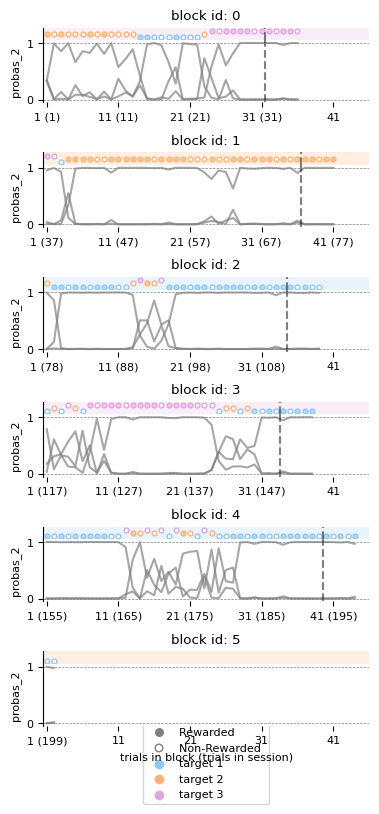

In [7]:

# plot behavior
##% imports
import pandas as pd
import matplotlib.pyplot as plt

from popy.io_tools import load_behavior, load_behavior_yuri, load_simulation
from popy.behavior_data_tools import *
from popy.plotting.plotting_tools import show_target_selection, show_target_selection_compact

# set fontsize to 8pt
plt.rcParams.update({'font.size': 8})

# target selection
#savedir = os.path.join('figs', 'example_session_compact.svg')
show_target_selection_compact(behavior_simulated[:200],   # here we can put any behavior dataframe
                              format='poster',
                              background_values=['probas_0', 'probas_1', 'probas_2'],   # here we tell what variable to use as background - value in this case
                              title=None, #f'monkey: {monkey}, session: {session}', 
                              show=True, 
                              )